# Health Study
## Part 1: Statistical Analysis

### 1. Data Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Läser in datasetet och kontrollera dess struktur och innehåll

df = pd.read_csv("../data/health_study_dataset.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

display(df.head())
display(df.dtypes.to_frame(name="Data type"))


Dataset shape: (800, 9)
Missing values: 0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


,Data type
id,int64
age,int64
sex,str
height,float64
weight,float64
systolic_bp,float64
cholesterol,float64
smoker,str
disease,int64


### Data validation
The dataset contains 800 rows and 9 columns. No missing values were found, and the data types appear suitable for further analysis.

### 2. Descriptive Statistics

In [2]:
# Väljer vilka kolumner jag ska undersöka
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# Använder agg för att beräkna flera statistiska mått samtidigt
stats = df[columns].agg(["mean", "median", "min", "max"]).T

# Avrundar resultatet till två decimaler och visar tabellen
stats = stats.round(2)
display(stats)


,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


### Results

The dataset contains 800 individuals. The mean age is 49.43 years, while the median age is 50 years. The youngest individual is 18 years old and the oldest is 90 years old.

The mean and median values are relatively close across the selected variables. All results have been rounded to two decimal places for better readability.

### 3. Data Visualization

#### 3.1 Blood Pressure Distribution

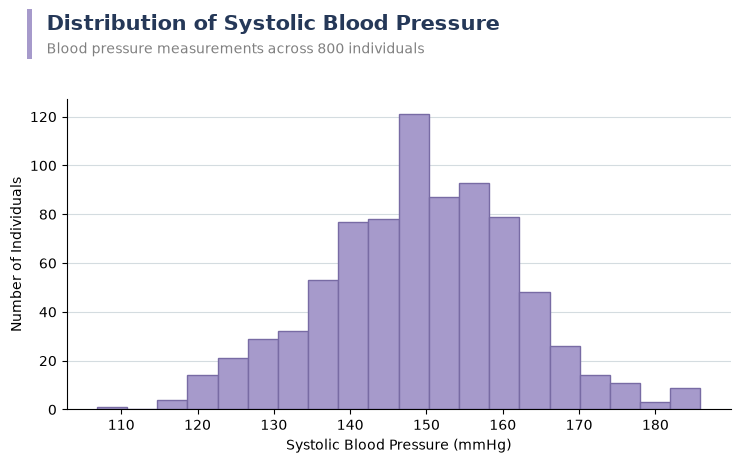

In [ ]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 5))

# Skapar histogrammet och anger designen
ax.hist(
    df["systolic_bp"],
    bins=20,
    color="#A69ACB",
    edgecolor="#786BA4",
    linewidth=1
)

# Lämnar plats ovanför diagrammet för rubrikerna
fig.subplots_adjust(top=0.76, left=0.13, right=0.96, bottom=0.14)

# Lägger till en lavendelfärgad accentlinje
accent = Rectangle(
    (0.08, 0.84),
    0.007,
    0.10,
    transform=fig.transFigure,
    facecolor="#A69ACB",
    edgecolor="none"
)
fig.add_artist(accent)

# Huvudrubrik
fig.text(
    0.105, 0.91,
    "Distribution of Systolic Blood Pressure",
    fontsize=15,
    fontweight="bold",
    color="#253858",
    ha="left",
    va="center"
)

# Underrubrik
fig.text(
    0.105, 0.86,
    f"Blood pressure measurements across {len(df)} individuals",
    fontsize=10,
    color="gray",
    ha="left",
    va="center"
)

# Axelrubriker
ax.set_xlabel("Systolic Blood Pressure (mmHg)")
ax.set_ylabel("Number of Individuals")

# Tydliga men diskreta stödlinjer
ax.grid(
    axis="y",
    color="#B8C5CC",
    alpha=0.6,
    linewidth=0.8
)
ax.set_axisbelow(True)

# Tar bort onödiga kanter
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.savefig("../figures/blood_pressure_distribution.png", dpi=300)
plt.show()

#### Results

Most systolic blood pressure values are concentrated between approximately 140 and 160 mmHg. The majority of values are found near the center of the distribution, with fewer observations at the lower and higher ends.

#### 3.2 Weight Distribution by Sex

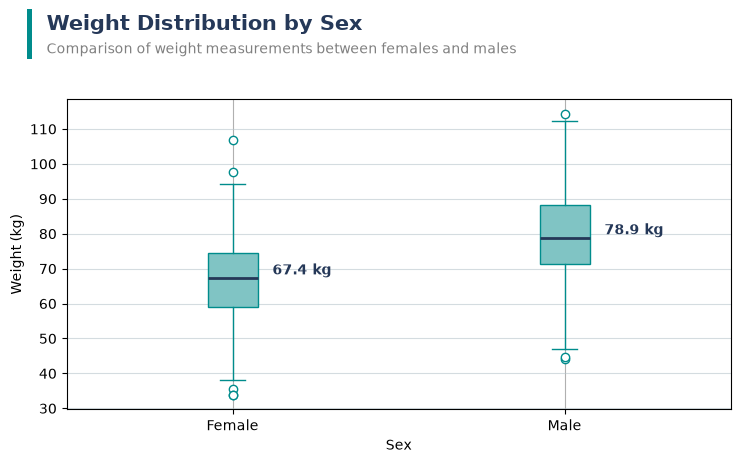

In [4]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 5))

# Skapar boxplot med turkos färgpalett
df.boxplot(
    column="weight",
    by="sex",
    ax=ax,
    patch_artist=True,
    boxprops=dict(
        facecolor="#80C4C4",
        edgecolor="#008C8C"
    ),
    medianprops=dict(
        color="#253858",
        linewidth=2
    ),
    whiskerprops=dict(color="#008C8C"),
    capprops=dict(color="#008C8C"),
    flierprops=dict(
        marker="o",
        markerfacecolor="white",
        markeredgecolor="#008C8C"
    )
)

# Tar bort Pandas automatiska rubriker
fig.suptitle("")
ax.set_title("")

# Lämnar plats för rubrikerna
fig.subplots_adjust(top=0.76, left=0.13, right=0.96, bottom=0.14)

# Lägger till en turkos accentlinje
accent = Rectangle(
    (0.08, 0.84),
    0.007,
    0.10,
    transform=fig.transFigure,
    facecolor="#008C8C",
    edgecolor="none"
)
fig.add_artist(accent)

# Huvudrubrik
fig.text(
    0.105, 0.91,
    "Weight Distribution by Sex",
    fontsize=15,
    fontweight="bold",
    color="#253858",
    ha="left",
    va="center"
)

# Underrubrik
fig.text(
    0.105, 0.86,
    "Comparison of weight measurements between females and males",
    fontsize=10,
    color="gray",
    ha="left",
    va="center"
)

# Anpassar axlarna
ax.set_xlabel("Sex")
ax.set_ylabel("Weight (kg)")
ax.set_xticklabels(["Female", "Male"])

# Gör stödlinjerna tydliga men diskreta
ax.grid(
    axis="y",
    color="#B8C5CC",
    alpha=0.6,
    linewidth=0.8
)

# Beräknar medianvikten för respektive kön
medians = df.groupby("sex")["weight"].median()

# Visar medianvärdena bredvid lådorna
for i, median in enumerate(medians, start=1):
    ax.text(
        i + 0.12,
        median,
        f"{median:.1f} kg",
        fontsize=10,
        fontweight="bold",
        color="#253858",
        va="bottom"
    )
fig.savefig("../figures/weight_distribution_by_sex.png", dpi=300)
plt.show()

In [5]:
# Undersöker viktstatistik för respektive kön
display(df.groupby("sex")["weight"].agg(["median", "min", "max"]).round(2))

# Kontrollerar observationen med ovanligt låg vikt
display(df.loc[df["weight"] == df["weight"].min()])

,median,min,max
sex,,,
F,67.4,33.7,106.9
M,78.9,44.1,114.4


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
709,710,75,F,149.6,33.7,159.1,5.0,Yes,0


### Results

The median weight is 67.4 kg for females and 78.9 kg for males, a difference of 11.5 kg.

The boxes represent the middle 50% of the values. For females, this range is approximately 59 to 74 kg, while for males it is approximately 71 to 88 kg.

The lines extending from the boxes show the range of values excluding outliers. Both groups have some outliers, represented by circles outside these lines.

The lowest recorded weight is 33.7 kg, which stands out in the boxplot. I examined this observation and found that the individual is 75 years old and 149.6 cm tall. Although the weight is unusually low, there is not enough information to determine whether it is an error.

#### 3.3 Smoking Distribution

smoker
No     73.38
Yes    26.62
Name: proportion, dtype: float64

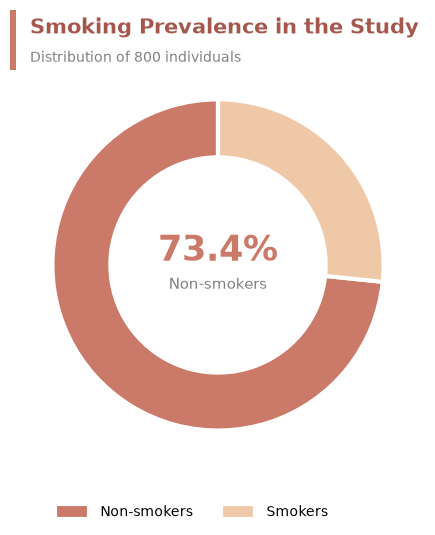

In [6]:
from matplotlib.patches import Rectangle

# Beräknar procentandelarna
smoking = df["smoker"].value_counts(normalize=True) * 100
display(smoking.round(2))

# Färgpalett
coral = "#CB7969"
peach = "#EFC9A7"
dark_coral = "#A6574D"
gray = "gray"

# Skapar figuren och placerar diagramytan
fig = plt.figure(figsize=(8, 6))
ax = fig.add_axes([0.08, 0.17, 0.52, 0.69])

# Skapar ringdiagrammet
wedges, _ = ax.pie(
    [smoking["No"], smoking["Yes"]],
    colors=[coral, peach],
    startangle=90,
    radius=1.0,
    wedgeprops=dict(
        width=0.35,
        edgecolor="white",
        linewidth=3
    )
)

# Accentlinje vid rubriken
fig.add_artist(
    Rectangle(
        (0.08, 0.84),
        0.007,
        0.10,
        transform=fig.transFigure,
        facecolor=coral,
        edgecolor="none"
    )
)

# Rubrik och underrubrik
fig.text(
    0.105, 0.91,
    "Smoking Prevalence in the Study",
    fontsize=15,
    fontweight="bold",
    color=dark_coral,
    ha="left",
    va="center"
)

fig.text(
    0.105, 0.86,
    f"Distribution of {len(df)} individuals",
    fontsize=10,
    color=gray,
    ha="left",
    va="center"
)

# Procentvärde och beskrivning i ringens mitt
ax.text(
    0, 0.08,
    f"{smoking['No']:.1f}%",
    ha="center",
    va="center",
    fontsize=25,
    fontweight="bold",
    color=coral
)

ax.text(
    0, -0.12,
    "Non-smokers",
    ha="center",
    va="center",
    fontsize=11,
    color=gray
)

# Färgförklaring under diagrammet
fig.legend(
    wedges,
    ["Non-smokers", "Smokers"],
    loc="lower left",
    bbox_to_anchor=(0.12, 0.07),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.5,
    handleheight=1.2
)
fig.savefig("../figures/smoking_prevalence.png", dpi=300)
plt.show()

### Results
The chart shows that 73.4% of the individuals are non-smokers, while 26.6% are smokers.

Non-smokers make up the majority of the dataset, representing almost three quarters of the individuals.

## 4. Simulation

In this section, we will use NumPy to simulate disease occurrence in a population of 1,000 individuals.

First, we calculate the proportion of individuals with the disease in the original dataset. We then use this proportion as the probability of disease in our simulation.

Finally, we compare the simulated proportion with the observed proportion to see how random variation can affect the results.

### 4.1 Observed Disease Prevalence

In [7]:
# Beräknar antalet personer med sjukdom
disease_count = df["disease"].sum()

# Beräknar andelen personer med sjukdom
disease_proportion = df["disease"].mean()

# Presenterar resultatet från det ursprungliga datasetet

print(f"In the original dataset, {disease_count} out of {len(df)} individuals were recorded as having a medical condition.")
print(f"This represents {disease_proportion * 100:.2f}% of the study population.\n")

# Visar sannolikheten som används i simuleringen
print(f"The probability used for the simulation is therefore: {disease_proportion}")




In the original dataset, 47 out of 800 individuals were recorded as having a medical condition.
This represents 5.88% of the study population.

The probability used for the simulation is therefore: 0.05875


### 4.2 Simulated Disease Prevalence

In [9]:
# Skapar en slumpgenerator med ett fast seed
rng = np.random.default_rng(42)

# Simulerar 1000 personer utifrån sannolikheten i datasetet
simulated_disease = rng.binomial(
    n=1,
    p=disease_proportion,
    size=1000
)

# Beräknar antal och andel personer med sjukdom i simuleringen
simulated_count = simulated_disease.sum()
simulated_proportion = simulated_disease.mean()

# Presenterar resultatet

print(f"Number of simulated individuals: {len(simulated_disease)}")
print(f"Individuals with a medical condition: {simulated_count}")
print(f"Simulated disease prevalence: {simulated_proportion * 100:.2f}%")

Number of simulated individuals: 1000
Individuals with a medical condition: 54
Simulated disease prevalence: 5.40%


### 4.3 Comparison of Observed and Simulated Results

We compare the observed disease prevalence with the simulated prevalence to examine the effect of random variation.

In [10]:
# Beräknar skillnaden mellan observerad och simulerad andel
difference = (simulated_proportion - disease_proportion) * 100

# Presenterar jämförelsen
print(f"Observed disease prevalence:  {disease_proportion * 100:.2f}%")
print(f"Simulated disease prevalence: {simulated_proportion * 100:.2f}%")
print(f"Difference: {difference:+.2f} percentage points")

Observed disease prevalence:  5.88%
Simulated disease prevalence: 5.40%
Difference: -0.47 percentage points


**Interpretation**

The simulated disease prevalence was slightly lower than the observed prevalence in the original dataset.

This difference illustrates random variation in the simulation. Even when using the same probability, the simulated proportion may differ from the observed proportion.